# Unsorted Spikes Visualization

In [1]:
session_dir = "../data/birds/GreYel3594M/GreYel3594M___170919_094646"

In [2]:
bird, session = session_dir.split("/")[-2:]

In [3]:
try:
    import cPickle as pickle
except ImportError:
    import pickle
import matplotlib.pyplot as plt
import numpy as np
import os

from sklearn.decomposition import PCA
from sklearn.manifold import TSNE

from segment_analysis import MultiSegment

import config

/auto/fhome/kevin/Projects/songephys/env/local/lib/python2.7/site-packages/h5py/__init__.py:34: FutureWarning: Conversion of the second argument of issubdtype from `float` to `np.floating` is deprecated. In future, it will be treated as `np.float64 == np.dtype(float).type`.
  from ._conv import register_converters as _register_converters


In [4]:
from ipywidgets import interact, widgets
%matplotlib notebook

In [24]:
data_path = os.path.join(session_dir, "spikes", "{}-thresholded.pkl").format(session)

In [25]:
with open(data_path, "rb") as datafile:
    block = pickle.load(datafile)

In [26]:
multiseg = MultiSegment(block.segments)

In [27]:
block.channel_indexes[2:]

[ChannelIndex with 1 units, 901 analogsignals name: 'Amp Elec 0',
 ChannelIndex with 1 units, 901 analogsignals name: 'Amp Elec 1',
 ChannelIndex with 1 units, 901 analogsignals name: 'Amp Elec 2',
 ChannelIndex with 1 units, 901 analogsignals name: 'Amp Elec 3',
 ChannelIndex with 1 units, 901 analogsignals name: 'Amp Elec 4',
 ChannelIndex with 1 units, 901 analogsignals name: 'Amp Elec 5',
 ChannelIndex with 1 units, 901 analogsignals name: 'Amp Elec 6',
 ChannelIndex with 1 units, 901 analogsignals name: 'Amp Elec 7',
 ChannelIndex with 1 units, 901 analogsignals name: 'Amp Elec 8',
 ChannelIndex with 1 units, 901 analogsignals name: 'Amp Elec 9',
 ChannelIndex with 1 units, 901 analogsignals name: 'Amp Elec 10',
 ChannelIndex with 1 units, 901 analogsignals name: 'Amp Elec 11',
 ChannelIndex with 1 units, 901 analogsignals name: 'Amp Elec 12',
 ChannelIndex with 1 units, 901 analogsignals name: 'Amp Elec 13',
 ChannelIndex with 1 units, 901 analogsignals name: 'Amp Elec 14',
 Chan

<IPython.core.display.Javascript object>


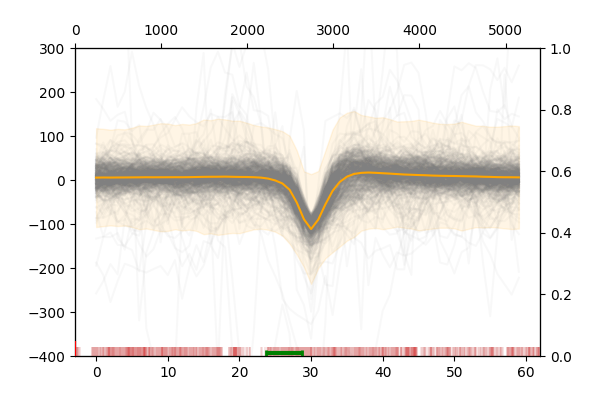

<IPython.core.display.Javascript object>


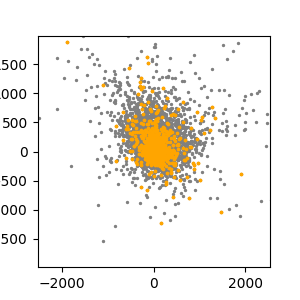

interactive(children=(Dropdown(description=u'Electrode:', options=(('Amp Elec 0', <neo.core.channelindex.ChannelIndex object at 0x7f1db3b80590>), ('Amp Elec 1', <neo.core.channelindex.ChannelIndex object at 0x7f1db3b80610>), ('Amp Elec 2', <neo.core.channelindex.ChannelIndex object at 0x7f1db3b80690>), ('Amp Elec 3', <neo.core.channelindex.ChannelIndex object at 0x7f1db3b80710>), ('Amp Elec 4', <neo.core.channelindex.ChannelIndex object at 0x7f1db3b80790>), ('Amp Elec 5', <neo.core.channelindex.ChannelIndex object at 0x7f1db3b80810>), ('Amp Elec 6', <neo.core.channelindex.ChannelIndex object at 0x7f1db3b80890>), ('Amp Elec 7', <neo.core.channelindex.ChannelIndex object at 0x7f1db3b80910>), ('Amp Elec 8', <neo.core.channelindex.ChannelIndex object at 0x7f1db3b80990>), ('Amp Elec 9', <neo.core.channelindex.ChannelIndex object at 0x7f1db3b80a10>), ('Amp Elec 10', <neo.core.channelindex.ChannelIndex object at 0x7f1db3b80a90>), ('Amp Elec 11', <neo.core.channelindex.ChannelIndex object at 0x7f1db3b80b10>), ('Amp Elec 12', <neo.core.channelindex.ChannelIndex object at 0x7f1db3b80b90>), ('Amp Elec 13', <neo.core.channelindex.ChannelIndex object at 0x7f1db3b80c10>), ('Amp Elec 14', <neo.core.channelindex.ChannelIndex object at 0x7f1db3b80c90>), ('Amp Elec 15', <neo.core.channelindex.ChannelIndex object at 0x7f1db3b80d10>)), value=<neo.core.channelindex.ChannelIndex object at 0x7f1db3b80590>), SelectionSlider(continuous_update=False, description=u't', options=(0.0, 60.0, 120.0, 180.0, 240.0, 300.0, 360.0, 420.0, 480.0, 540.0, 600.0, 660.0, 720.0, 780.0, 840.0, 900.0, 960.0, 1020.0, 1080.0, 1140.0, 1200.0, 1260.0, 1320.0, 1380.0, 1440.0, 1500.0, 1560.0, 1620.0, 1680.0, 1740.0, 1800.0, 1860.0, 1920.0, 1980.0, 2040.0, 2100.0, 2160.0, 2220.0, 2280.0, 2340.0, 2400.0, 2460.0, 2520.0, 2580.0, 2640.0, 2700.0, 2760.0, 2820.0, 2880.0, 2940.0, 3000.0, 3060.0, 3120.0, 3180.0, 3240.0, 3300.0, 3360.0, 3420.0, 3480.0, 3540.0, 3600.0, 3660.0, 3720.0, 3780.0, 3840.0, 3900.0, 3960.0, 4020.0, 4080.0, 4140.0, 4200.0, 4260.0, 4320.0, 4380.0, 4440.0, 4500.0, 4560.0, 4620.0, 4680.0, 4740.0, 4800.0, 4860.0, 4920.0, 4980.0, 5040.0, 5100.0, 5160.0, 5220.0, 5280.0, 5340.0), value=0.0), SelectionSlider(continuous_update=False, description=u't_window', index=9, options=(60.0, 120.0, 180.0, 240.0, 300.0, 360.0, 420.0, 480.0, 540.0, 600.0, 660.0, 720.0, 780.0, 840.0, 900.0, 960.0, 1020.0, 1080.0, 1140.0, 1200.0, 1260.0, 1320.0, 1380.0, 1440.0, 1500.0, 1560.0, 1620.0, 1680.0, 1740.0), value=600.0), Output()), _dom_classes=('widget-interact',))

In [28]:
fig, axes = plt.subplots(nrows=1, ncols=1, figsize=(6, 4))
scatter_fig, scatter_ax = plt.subplots(nrows=1, ncols=1, figsize=(3, 3))

total_t = 90.0 * 60.0
segment_ax = axes.twinx().twiny()
time_ax = segment_ax.twinx()

window_slider = widgets.SelectionSlider(
    options=np.arange(60.0, 30.0 * 60.0, 60.0),
    value=2.0 * 60.0,
    disabled=False,
    continuous_update=False,
    orientation='horizontal',
    readout=True,
    readout_format='.1f',
)

t_slider = widgets.SelectionSlider(
    options=np.arange(0.0, 90 * 60.0, 60.0),
    value=0.0,
    disabled=False,
    continuous_update=False,
    orientation='horizontal',
    readout=True,
    readout_format='.1f',
)

electrode_dropdown = widgets.Dropdown(
    options=[(c.name, c) for c in block.channel_indexes[2:]],
    value=block.channel_indexes[2],
    description='Electrode:',
    disabled=False,
)

elec_data = {}
def select_unit(elec, t, t_window):
    t = (t, t + t_window)
    axes.clear()
    scatter_ax.clear()
    axes.set_ylim(-400, 300)
    update_timebar(t)
    unit = elec.units[0]
    
    segment_ax.clear()
    segment_ax.set_xlim(0, total_t)
    segment_ax.set_ylim(0, 1)
    segment_ax.vlines([st.t_start for st in unit.spiketrains], 0, 0.03, color="Gray", linewidth=0.1)
    segment_ax.vlines([st.t_start for st in unit.spiketrains if len(st.times)], 0, 0.03, color="Red", linewidth=0.1)

    if elec not in elec_data:
        times = np.concatenate([st.times for st in unit.spiketrains if len(st.waveforms)])
        spikes = np.concatenate([st.waveforms for st in unit.spiketrains if len(st.waveforms)])
        elec_data[elec] = {
            "times": times,
            "spikes": spikes,
        }
    else:
        times = elec_data[elec]["times"]
        spikes = elec_data[elec]["spikes"]
        
    selector = (times >= t[0]) & (times < t[1])

    pca = PCA(n_components=2)
    all_2d_data = pca.fit_transform(spikes)
    scatter_mean = np.mean(all_2d_data, axis=0)
    scatter_std = np.std(all_2d_data, axis=0)
        
    if not len(spikes[selector]):
        pass
    else:
        skip = int(np.ceil(len(spikes[selector]) / 500.0))
        print("ay", selector)
        axes.plot(spikes[selector][::skip].T, alpha=0.05, color="Gray")
        mu = np.mean(spikes[selector], axis=0)
        sigma = np.std(spikes[selector], axis=0)
        axes.fill_between(np.arange(len(mu)), mu - 3 * sigma, mu + 3 * sigma, color="Orange", alpha=0.1)
        axes.plot(mu, color="Orange")
        
        scatter_ax.scatter(*all_2d_data.T, s=2, color="Gray")
        print(scatter_ax.scatter(*pca.transform(spikes[selector]).T, s=3, color="Orange"))
        scatter_ax.set_xlim(scatter_mean[0] - 3 * scatter_std[0], scatter_mean[0] + 3 * scatter_std[0])
        scatter_ax.set_ylim(scatter_mean[1] - 3 * scatter_std[1], scatter_mean[1] + 3 * scatter_std[1])

        scatter_fig.canvas.draw()
        fig.canvas.draw()
    
def update_timebar(t):
    time_ax.clear()
    time_ax.set_xlim(0, total_t)
    time_ax.set_ylim(0, 1)
    time_ax.axis("off")
    
    time_ax.vlines([0, 1], 0, 0.05, color="Red")
    time_ax.vlines(t, 0, 0.02, color="Green", linewidth=2)
    time_ax.hlines([0.01], *t, color="Green", linewidth=3)
    
display(widgets.interactive(select_unit, elec=electrode_dropdown, t=t_slider, t_window=window_slider))
